# Task 2 – Content Type Prediction (Movie vs TV Show)

**Goal:** predict whether a Netflix title is a **Movie** or a **TV Show** from its other attributes. This is a *binary classification* problem.

**The trap I need to avoid:** the `duration` column says "90 min" for movies and "2 Seasons" for shows, so using it would give a perfect score for the wrong reason. This is called *data leakage*. I'll prove it below and then leave `duration` out. I'll also show a second, more hidden leak in the genre names.

In [3]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Step 0 – Load and clean the data

Before any modelling I load the file and tidy it. What I do, and why:

- **Remove exact duplicate rows** (there are none in this file, but it is a good habit).
- **Parse `date_added`.** In this dataset dates look like `9/25/2021`, so I tell pandas the exact format.
- **Missing values** are not blank here. The file writes `Not Given` for unknown directors and countries, and I keep that in mind (for example `has_director` is 0 when the director is `Not Given`).
- **Turn `duration` into a number.** `"90 min"` becomes 90 and `"2 Seasons"` becomes 2.
- **Simplify genre names.** Netflix names the same genre differently for movies and shows (`Dramas` vs `TV Dramas`, `International Movies` vs `International TV Shows`). I merge them so a genre means the same thing for both types.

In [4]:
DATA_PATH = "Dataset.csv"      # change this if the file is in another folder

df = pd.read_csv(DATA_PATH).drop_duplicates().reset_index(drop=True)
print("Dataset shape:", df.shape)

# Dates (format in this file is month/day/year)
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%m/%d/%Y", errors="coerce")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

# Duration as a number: "90 min" -> 90, "2 Seasons" -> 2
df["duration_num"] = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")

# Helpers for comma separated columns
def split_items(text):
    return [p.strip() for p in str(text).split(",") if p.strip()]

def simplify_genre(name):
    """'TV Dramas' and 'Dramas' -> 'Dramas';  'International Movies' -> 'International'."""
    name = name.strip()
    if name in ("Movies", "TV Shows"):
        return "Other"
    name = re.sub(r"^TV\s+", "", name)
    name = re.sub(r"\s+(Movies|TV Shows|TV)$", "", name)
    return name

# Handy columns used by several tasks
df["genre_list"] = df["listed_in"].apply(lambda s: [simplify_genre(g) for g in split_items(s)])
df["n_genres"] = df["genre_list"].apply(len)
df["country_main"] = df["country"].apply(lambda s: split_items(s)[0] if split_items(s) else "Not Given")
df["has_director"] = (df["director"].str.strip() != "Not Given").astype(int)
df["years_to_add"] = (df["year_added"] - df["release_year"]).clip(lower=0)

# 0/1 columns for the 30 most common (simplified) genres, most common first
top_genres = pd.Series([g for lst in df["genre_list"] for g in lst]).value_counts().head(30).index.tolist()
genre_cols = []
for g in top_genres:
    col = "genre_" + g
    df[col] = df["genre_list"].apply(lambda lst, g=g: int(g in lst))
    genre_cols.append(col)

print(df["type"].value_counts().to_dict(), "| date range:", df["date_added"].min().date(), "to", df["date_added"].max().date())
df.head(3)

Dataset shape: (8790, 10)
{'Movie': 6126, 'TV Show': 2664} | date range: 2008-01-01 to 2021-09-25


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,...,genre_Spanish-Language,genre_Korean,genre_Classic,genre_LGBTQ,genre_Mysteries,genre_Science & Nature,genre_Cult,genre_Anime Features,genre_Other,genre_Teen
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,...,0,0,0,0,0,0,0,0,0,0
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",...,0,0,0,0,0,0,0,0,0,0
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",...,0,0,0,0,1,0,0,0,0,0


## Step 1 – Select relevant features

First, let me prove the leakage problem so the choice of features is justified.

In [5]:
# Leak #1: duration alone predicts the type perfectly
rule = df["duration"].str.contains("Season")
print("'Duration contains Season' matches the type in", f"{(rule == (df['type'] == 'TV Show')).mean():.1%}", "of rows")

# Leak #2: raw genre names like "TV Dramas" / "International Movies" give the type away
df["genre_main_raw"] = df["listed_in"].apply(lambda s: split_items(s)[0])
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    df[["genre_main_raw"]], df["type"], test_size=0.2, stratify=df["type"], random_state=RANDOM_STATE)
leaky = Pipeline([("prep", ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), ["genre_main_raw"])])),
                  ("m", DecisionTreeClassifier(random_state=RANDOM_STATE))]).fit(Xl_train, yl_train)
print("Accuracy from raw genre names alone:", f"{accuracy_score(yl_test, leaky.predict(Xl_test)):.1%}")

'Duration contains Season' matches the type in 100.0% of rows
Accuracy from raw genre names alone: 100.0%


Both leaks are real. To keep the model honest I:
- **drop `duration`** completely, and
- use my **simplified genres** (e.g. "TV Dramas" and "Dramas" both become "Dramas"), so the model has to learn from the *kind* of content and not from the words "TV" or "Movies" in the label.

**Features I'll use:** release year, year and month added, years between release and being added, number of genres, whether a director is listed, rating, main country, and 0/1 columns for the 30 most common genres.

In [6]:
numeric_features = (["release_year", "year_added", "month_added", "years_to_add", "n_genres", "has_director"]
                    + genre_cols)
categorical_features = ["rating", "country_main"]

X = df[numeric_features + categorical_features]
y = (df["type"] == "TV Show").astype(int)     # 0 = Movie, 1 = TV Show

print("Number of features before encoding:", X.shape[1])
print(y.value_counts(normalize=True).rename({0: "Movie", 1: "TV Show"}).round(3))

Number of features before encoding: 38
type
Movie      0.697
TV Show    0.303
Name: proportion, dtype: float64


## Step 2 – Encode categorical variables

Models need numbers, so I use **one-hot encoding**: a category like `TV-MA` becomes its own 0/1 column. Rare categories (fewer than 10 titles) are grouped together, and unseen categories at prediction time are safely ignored. Numeric columns are scaled so that, for example, `release_year` doesn't overpower a 0/1 column in Logistic Regression.

## Step 3 – Train classification models

I split the data 80/20, and `stratify=y` keeps the Movie/TV Show proportion the same in both parts. I train three models, from simple to powerful:
- **Logistic Regression** – a simple linear baseline.
- **Decision Tree** – learns easy-to-read if/else rules.
- **Random Forest** – many trees voting together, usually the most accurate.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), categorical_features),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}

fitted, predictions, rows = {}, {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", clf)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name], predictions[name] = pipe, pred
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.9858,0.9774,0.9756,0.9765
Decision Tree,0.9829,0.9809,0.9625,0.9716
Random Forest,0.9869,0.9811,0.9756,0.9784


## Step 4 – Evaluate prediction performance

How to read the metrics (treating "TV Show" as the positive class):
- **Precision:** of the titles I called TV Shows, how many really were.
- **Recall:** of all real TV Shows, how many I found.
- **F1:** the balance of the two. Since there are about 2.3 Movies for every TV Show, accuracy alone can flatter a model, so I look at F1 too.

I also run a **5-fold cross-validation** on the best model to check that the score isn't just luck from one particular split. (I shuffle the rows first, because this file is sorted by date and un-shuffled folds would each see a different era of Netflix.)

Best model by F1: Random Forest

              precision    recall  f1-score   support

       Movie       0.99      0.99      0.99      1225
     TV Show       0.98      0.98      0.98       533

    accuracy                           0.99      1758
   macro avg       0.99      0.98      0.98      1758
weighted avg       0.99      0.99      0.99      1758

5-fold cross-validated F1: 0.9774 (+/- 0.0056)


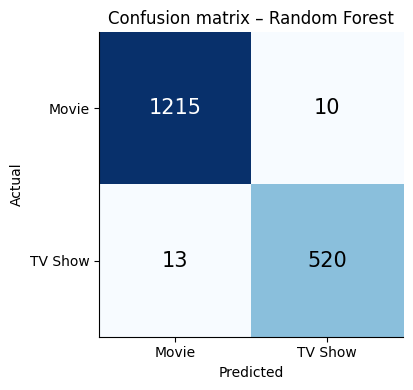

In [8]:
best_name = results["F1"].idxmax()
print("Best model by F1:", best_name)
print()
print(classification_report(y_test, predictions[best_name], target_names=["Movie", "TV Show"]))

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # shuffle: the file is sorted by date
cv_scores = cross_val_score(fitted[best_name], X, y, cv=folds, scoring="f1")
print(f"5-fold cross-validated F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

cm = confusion_matrix(y_test, predictions[best_name])
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Movie", "TV Show"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Movie", "TV Show"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=15,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title(f"Confusion matrix – {best_name}")
plt.tight_layout()
plt.show()

## Step 5 – Compare model accuracy

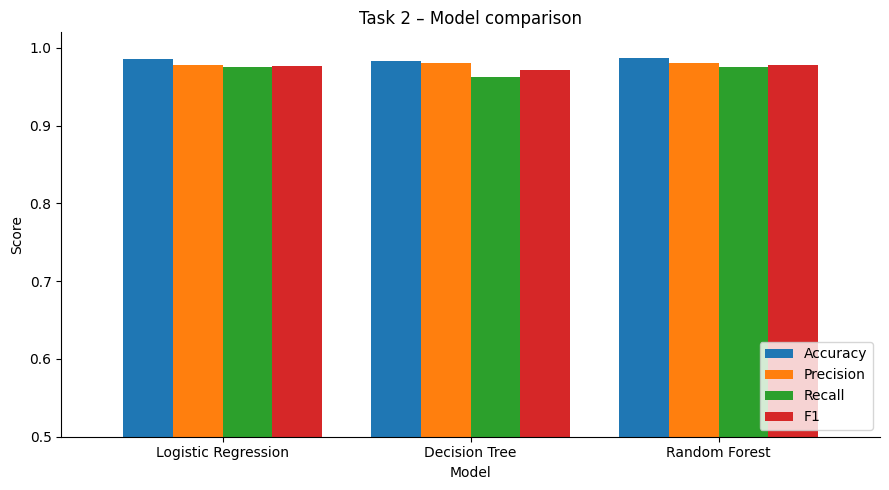

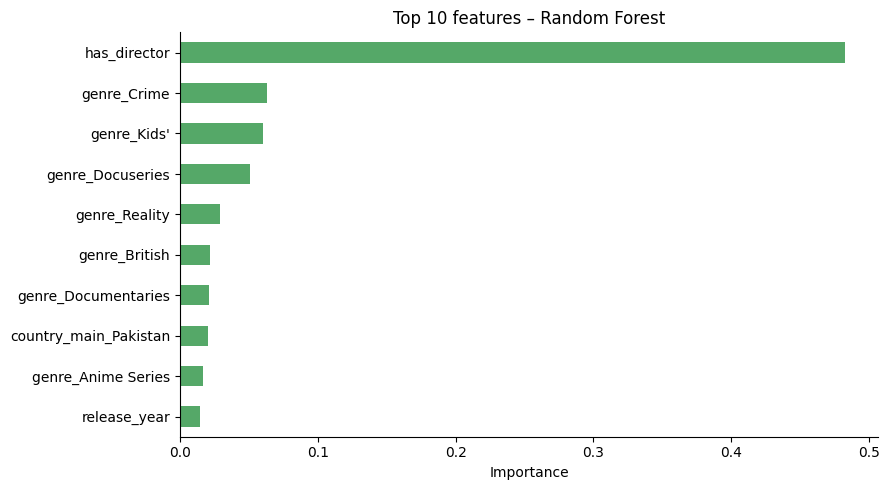

In [9]:
results.plot(kind="bar", rot=0, ylim=(0.5, 1.02), width=0.8)
plt.title("Task 2 – Model comparison")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Which features did the Random Forest rely on?
rf_pipe = fitted["Random Forest"]
names = [n.replace("num__", "").replace("cat__", "") for n in rf_pipe.named_steps["prep"].get_feature_names_out()]
importance = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names)
importance.sort_values().tail(10).plot(kind="barh", color="#55a868")
plt.title("Top 10 features – Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Conclusion

- All three models predict Movie vs TV Show well without using `duration`. The table above shows the exact scores, and the Random Forest (or the best model by F1) is my pick.
- The feature-importance chart shows what the model leans on. Whether a director is listed is a strong clue, because TV shows rarely have a single director credited.
- **The lesson:** with `duration` or raw genre names, the score would look near-perfect but would be meaningless. Removing leakage is what makes this result trustworthy.